# Telco Customer Churn and Retention Analytics

## Business Context

Customer churn is an important business concern for telecommunications companies because losing customers can affect customer retention and future revenue. Understanding how churn varies across customer groups can help a business identify areas that may require further investigation and targeted retention efforts.

## Project Objective

The objective of this project is to analyse customer churn patterns and identify customer characteristics, service usage patterns, pricing differences, and other factors associated with churn. The analysis aims to provide business-relevant insights that can support further investigation into customer retention opportunities.

## Analytical Approach

The project uses Python to explore customer data, examine churn rates across different customer segments, and visualise patterns in customer behaviour and characteristics. The analysis covers demographics, tenure, contracts, charges, customer satisfaction, internet services, offers, and geographic differences. Customer-reported reasons for churn are also examined to understand the concerns reported by departing customers.

## Scope

This project focuses on exploratory and descriptive analytics rather than building a predictive churn model. The findings are used to identify associations and potential areas for further investigation, rather than establish causal relationships.


### 1. Data Loading and Inspection

#### Importing Libraries

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
import plotly.express as px
import plotly.graph_objects as go
import warnings 
warnings.filterwarnings('ignore')


sns.set_style('whitegrid')
sns.set_palette('rainbow')

In [2]:
df=pd.read_csv('telco.csv')
print(f'Shape: {df.shape[0]} rows and {df.shape[1]} columns')

Shape: 7043 rows and 50 columns


#### Dataset Description
- `CustomerID`: A unique ID that identifies each customer.
- `Gender`: The customer’s gender: Male, Female
- `Age`: The customer’s current age, in years, at the time the fiscal quarter ended.
- `Senior Citizen`: Indicates if the customer is 65 or older: Yes, No
- `Married`: Indicates if the customer is married: Yes, No
- `Dependents`: Indicates if the customer lives with any dependents: Yes, No. Dependents could be children, parents, grandparents, etc.
- `Number of Dependents`: Indicates the number of dependents that live with the customer.
- `Country`: The country of the customer’s primary residence.
- `State`: The state of the customer’s primary residence.
- `City`: The city of the customer’s primary residence.
- `Zip Code`: The zip code of the customer’s primary residence.
- `Latitude`: The latitude of the customer’s primary residence.
- `Longitude`: The longitude of the customer’s primary residence.
- `Population`: A current population estimate for the entire Zip Code area.
- `Quarter`: The fiscal quarter that the data has been derived from (e.g. Q3).
- `Referred a Friend`: Indicates if the customer has ever referred a friend or family member to this company: Yes, No
- `Number of Referrals`: Indicates the number of referrals to date that the customer has made.
- `Tenure in Months`: Indicates the total amount of months that the customer has been with the company by the end of the quarter specified above.
- `Offer`: Identifies the last marketing offer that the customer accepted, if applicable. Values include None, Offer A, Offer B, Offer C, Offer D, and Offer E.
- `Phone Service`: Indicates if the customer subscribes to home phone service with the company: Yes, No
- `Avg Monthly Long Distance Charges`: Indicates the customer’s average long distance charges, calculated to the end of the quarter specified above.
- `Multiple Lines`: Indicates if the customer subscribes to multiple telephone lines with the company: Yes, No
- `Internet Service`: Indicates if the customer subscribes to Internet service with the company: No, DSL, Fiber Optic, Cable.
- `Avg Monthly GB Download`: Indicates the customer’s average download volume in gigabytes, calculated to the end of the quarter specified above.
- `Online Security`: Indicates if the customer subscribes to an additional online security service provided by the company: Yes, No
- `Online Backup`: Indicates if the customer subscribes to an additional online backup service provided by the company: Yes, No
- `Device Protection Plan`: Indicates if the customer subscribes to an additional device protection plan for their Internet equipment provided by the company: Yes, No
- `Premium Tech Support`: Indicates if the customer subscribes to an additional technical support plan from the company with reduced wait times: Yes, No
- `Streaming TV`: Indicates if the customer uses their Internet service to stream television programing from a third party provider: Yes, No. The company does not charge an additional fee for this service.
- `Streaming Movies`: Indicates if the customer uses their Internet service to stream movies from a third party provider: Yes, No. The company does not charge an additional fee for this service.
- `Streaming Music`: Indicates if the customer uses their Internet service to stream music from a third party provider: Yes, No. The company does not charge an additional fee for this service.
- `Unlimited Data`: Indicates if the customer has paid an additional monthly fee to have unlimited data downloads/uploads: Yes, No
- `Contract`: Indicates the customer’s current contract type: Month-to-Month, One Year, Two Year.
- `Paperless Billing`: Indicates if the customer has chosen paperless billing: Yes, No
- `Payment Method`: Indicates how the customer pays their bill: Bank Withdrawal, Credit Card, Mailed Check
- `Monthly Charge`: Indicates the customer’s current total monthly charge for all their services from the company.
- `Total Charges`: Indicates the customer’s total charges, calculated to the end of the quarter specified above.
- `Total Refunds`: Indicates the customer’s total refunds, calculated to the end of the quarter specified above.
- `Total Extra Data Charges`: Indicates the customer’s total charges for extra data downloads above those specified in their plan, by the end of the quarter specified above.
- `Total Long Distance Charges`: Indicates the customer’s total charges for long distance above those specified in their plan, by the end of the quarter specified above.
- `Satisfaction Score`: A customer’s overall satisfaction rating of the company from 1 (Very Unsatisfied) to 5 (Very Satisfied).
- `Customer Status`: Indicates the status of the customer at the end of the quarter: Churned, Stayed, or Joined
- `Churn Label`: Yes = the customer left the company this quarter. No = the customer remained with the company. Directly related to Churn Value.
- `Churn Score`: A value from 0-100 that is calculated using the predictive tool IBM SPSS Modeler. The model incorporates multiple factors known to cause churn. The higher the score, the more likely the customer will churn.
- `CLTV`: Customer Lifetime Value. A predicted CLTV is calculated using corporate formulas and existing data. The higher the value, the more valuable the customer. High value customers should be monitored for churn.
- `Churn Category`: A high-level category for the customer’s reason for churning: Attitude, Competitor, Dissatisfaction, Other, Price. When they leave the company, all customers are asked about their reasons for leaving. Directly related to Churn Reason.
- `Churn Reason`: A customer’s specific reason for leaving the company. Directly related to Churn Category

#### Data Inspection

In [3]:
df.head(3)

,Customer ID,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,Country,State,...,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Score,CLTV,Churn Category,Churn Reason
0,8779-QRDMV,Male,78,No,Yes,No,No,0,United States,California,...,20,0.00,59.65,3,Churned,Yes,91,5433,Competitor,Competitor offered more data
1,7495-OOKFY,Female,74,No,Yes,Yes,Yes,1,United States,California,...,0,390.80,1024.10,3,Churned,Yes,69,5302,Competitor,Competitor made better offer
2,1658-BYGOY,Male,71,No,Yes,No,Yes,3,United States,California,...,0,203.94,1910.88,2,Churned,Yes,81,3179,Competitor,Competitor made better offer


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 50 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Under 30                           7043 non-null   str    
 4   Senior Citizen                     7043 non-null   str    
 5   Married                            7043 non-null   str    
 6   Dependents                         7043 non-null   str    
 7   Number of Dependents               7043 non-null   int64  
 8   Country                            7043 non-null   str    
 9   State                              7043 non-null   str    
 10  City                               7043 non-null   str    
 11  Zip Code                           7043 non-null   int64  
 12  Lat

In [5]:
# Statistical Summary (Numeric Columns)
df.describe()

,Age,Number of Dependents,Zip Code,Latitude,Longitude,Population,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Churn Score,CLTV
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,46.509726,0.468692,93486.070567,36.197455,-119.756684,22139.603294,1.951867,32.386767,22.958954,20.515405,64.761692,2280.381264,1.962182,6.860713,749.099262,3034.379056,3.244924,58.505040,4400.295755
std,16.750352,0.962802,1856.767505,2.468929,2.154425,21152.392837,3.001199,24.542061,15.448113,20.418940,30.090047,2266.220462,7.902614,25.104978,846.660055,2865.204542,1.201657,21.170031,1183.057152
min,19.000000,0.000000,90001.000000,32.555828,-124.301372,11.000000,0.000000,1.000000,0.000000,0.000000,18.250000,18.800000,0.000000,0.000000,0.000000,21.360000,1.000000,5.000000,2003.000000
25%,32.000000,0.000000,92101.000000,33.990646,-121.788090,2344.000000,0.000000,9.000000,9.210000,3.000000,35.500000,400.150000,0.000000,0.000000,70.545000,605.610000,3.000000,40.000000,3469.000000
50%,46.000000,0.000000,93518.000000,36.205465,-119.595293,17554.000000,0.000000,29.000000,22.890000,17.000000,70.350000,1394.550000,0.000000,0.000000,401.440000,2108.640000,3.000000,61.000000,4527.000000
75%,60.000000,0.000000,95329.000000,38.161321,-117.969795,36125.000000,3.000000,55.000000,36.395000,27.000000,89.850000,3786.600000,0.000000,0.000000,1191.100000,4801.145000,4.000000,75.500000,5380.500000
max,80.000000,9.000000,96150.000000,41.962127,-114.192901,105285.000000,11.000000,72.000000,49.990000,85.000000,118.750000,8684.800000,49.790000,150.000000,3564.720000,11979.340000,5.000000,96.000000,6500.000000


In [6]:
# Statistical Summary (Non-numeric Columns)
df.describe(include='str')

,Customer ID,Gender,Under 30,Senior Citizen,Married,Dependents,Country,State,City,Quarter,...,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Customer Status,Churn Label,Churn Category,Churn Reason
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043,1869,1869
unique,7043,2,2,2,2,2,1,1,1106,1,...,2,2,2,3,2,3,3,2,5,20
top,8779-QRDMV,Male,No,No,No,No,United States,California,Los Angeles,Q3,...,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,Stayed,No,Competitor,Competitor had better devices
freq,1,3555,5642,5901,3641,5416,7043,7043,293,7043,...,4311,4555,4745,3610,4171,3909,4720,5174,841,313


In [7]:
# Number of unique values per column 
df.nunique()

Customer ID                          7043
Gender                                  2
Age                                    62
Under 30                                2
Senior Citizen                          2
Married                                 2
Dependents                              2
Number of Dependents                   10
Country                                 1
State                                   1
City                                 1106
Zip Code                             1626
Latitude                             1626
Longitude                            1625
Population                           1569
Quarter                                 1
Referred a Friend                       2
Number of Referrals                    12
Tenure in Months                       72
Offer                                   5
Phone Service                           2
Avg Monthly Long Distance Charges    3584
Multiple Lines                          2
Internet Service                  

In [8]:
# Checking for duplicates
print('Count of fully duplicated rows: ',df.duplicated().sum())

Count of fully duplicated rows:  0


In [9]:
# Checking for null values
df.isnull().sum()

Customer ID                             0
Gender                                  0
Age                                     0
Under 30                                0
Senior Citizen                          0
Married                                 0
Dependents                              0
Number of Dependents                    0
Country                                 0
State                                   0
City                                    0
Zip Code                                0
Latitude                                0
Longitude                               0
Population                              0
Quarter                                 0
Referred a Friend                       0
Number of Referrals                     0
Tenure in Months                        0
Offer                                3877
Phone Service                           0
Avg Monthly Long Distance Charges       0
Multiple Lines                          0
Internet Service                  

In [10]:
pd.set_option('display.max_columns', None)

In [11]:
# Displaying all unique categories in each categorical column
cat_cols= df.select_dtypes(include='str').columns.drop('Customer ID')
for col in cat_cols:
    print(f"{col}: {df[col].unique()}")

Gender: <StringArray>
['Male', 'Female']
Length: 2, dtype: str
Under 30: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Senior Citizen: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Married: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Dependents: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Country: <StringArray>
['United States']
Length: 1, dtype: str
State: <StringArray>
['California']
Length: 1, dtype: str
City: <StringArray>
[    'Los Angeles',       'Inglewood',        'Whittier',     'Pico Rivera',
    'Los Alamitos',    'Sierra Madre',        'Pasadena', 'North Hollywood',
          'Covina',        'El Monte',
 ...
    'Markleeville',         'Calpine',        'Tulelake',       'Boulevard',
          'Niland', 'Wofford Heights',         'Alturas',           'Topaz',
         'Jacumba',       'Holtville']
Length: 1106, dtype: str
Quarter: <StringArray>
['Q3']
Length: 1, dtype: str
Referred a Friend: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Offer: <Stri

#### Data Quality Findings:
1. There are no fully duplicated rows and customer ids which means every row represents a unique customer
2. There are 3 columns with null values, in the `Internet Type` and `Offer` columns, these null values correspond to None option. While in `Churn Category` and `Churn Reason`, the nulls correspond to customers who haven't churned.
3. All invalid categories have been identified to correspond to None option.
4. All numeric columns fall within reasonable ranges, except anomalies in the population column with some cities like Malibu having a population of below 20

### 2. Data Cleaning and Preparation

In [12]:
# Creating a copy of the data for the data cleaning process
df_clean = df.copy()
df_clean.shape

(7043, 50)

In [13]:
# ---- Step 1: Handle missing values---
# We have to fill the NaN values as None in the Internet Type and Offer columns.
df_clean[['Internet Type', 'Offer']] = df_clean[['Internet Type', 'Offer']].fillna('None')
print(df_clean['Internet Type'].value_counts(dropna=False))
print(df_clean['Offer'].value_counts(dropna=False))

Internet Type
Fiber Optic    3035
DSL            1652
None           1526
Cable           830
Name: count, dtype: int64
Offer
None       3877
Offer B     824
Offer E     805
Offer D     602
Offer A     520
Offer C     415
Name: count, dtype: int64


In [14]:
# -----Step 2: Dropping Noise: Quarter, Country, State-----
# These columns share the same values for all records, providing no variation for analysis
df_clean= df_clean.drop(['Quarter','Country', 'State'],axis=1)

In [15]:
print('Count of duplicates:', df_clean.duplicated().sum())

Count of duplicates: 0


In [16]:
df_clean.shape

(7043, 47)

#### Feature Engineering 

In [17]:
# Grouping Age, Tenure, Avg GB Download, Monthly Charges, Total Charges, Total Revenue, CLTV into bins for deeper analysis

# Age
df_clean['Age Group'] = pd.cut(
    df_clean['Age'],
    bins=[17, 29, 39, 49, 59, 69, 80],
    labels=['18-29', '30-39', '40-49', '50-59', '60-69', '70-80']
)

# Grouping Tenure 

bins = [0, 12, 24, 36, 48, 60, 72]

df_clean["Tenure Groups"] = pd.cut(
    df_clean["Tenure in Months"],
    bins=bins,
    labels=[
        "1-12 Months",
        "13-24 Months",
        "25-36 Months",
        "37-48 Months",
        "49-60 Months",
        "61-72 Months"
    ]
)
# Grouping GB Downloads
bins = [0, 3, 17, 27, 85]
df_clean["GB Download Groups"] = pd.cut(
    df_clean["Avg Monthly GB Download"],
    bins=bins,
    labels=[
        "Low",
        "Lower-Medium",
        "Upper-Medium",
        "High"
    ],
    include_lowest=True
)
# Monthly Charges 
bins = [0, 36, 70, 90, 120]
df_clean['Monthly Charge Groups'] = pd.cut(
    df_clean['Monthly Charge'],
    bins=bins,
    labels=['0-36', '>36-70', '>70-90', '>90-120'],
    include_lowest=True
)
# Total Charges 
bins= [0,400,1400,3800,9000]
df_clean['Total Charge Group']=pd.cut(df_clean['Total Charges'],bins=bins, 
        labels=['0–400', '>400–1,400', '>1,400–3,800','>3,800–9,000'], include_lowest=True)

# Total Revenue
bins= [0,600,2100,4800,12000]
df_clean['Total Revenue Group']=pd.cut(df_clean['Total Revenue'],bins=bins, 
        labels=['0–600', '>600–2,100', '>2,100–4,800','>4,800–12,000'], include_lowest=True)

# CLTV
bins = [2000, 2500, 3000, 3500, 4000, 4500, 5000, 5500, 6000, 6500, 7000]
labels = [
    '2000-2500',
    '2501-3000',
    '3001-3500',
    '3501-4000',
    '4001-4500',
    '4501-5000',
    '5001-5500',
    '5501-6000',
    '6001-6500',
    '6501-7000'
]
df_clean['CLTV Group'] = pd.cut(
    df_clean['CLTV'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [18]:
df_clean.head(3)

,Customer ID,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,City,Zip Code,Latitude,Longitude,Population,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Score,CLTV,Churn Category,Churn Reason,Age Group,Tenure Groups,GB Download Groups,Monthly Charge Groups,Total Charge Group,Total Revenue Group,CLTV Group
0,8779-QRDMV,Male,78,No,Yes,No,No,0,Los Angeles,90022,34.023810,-118.156582,68701,No,0,1,None,No,0.00,No,Yes,DSL,8,No,No,Yes,No,No,Yes,No,No,Month-to-Month,Yes,Bank Withdrawal,39.65,39.65,0.00,20,0.00,59.65,3,Churned,Yes,91,5433,Competitor,Competitor offered more data,70-80,1-12 Months,Lower-Medium,>36-70,0–400,0–600,5001-5500
1,7495-OOKFY,Female,74,No,Yes,Yes,Yes,1,Los Angeles,90063,34.044271,-118.185237,55668,Yes,1,8,Offer E,Yes,48.85,Yes,Yes,Fiber Optic,17,No,Yes,No,No,No,No,No,Yes,Month-to-Month,Yes,Credit Card,80.65,633.30,0.00,0,390.80,1024.10,3,Churned,Yes,69,5302,Competitor,Competitor made better offer,70-80,1-12 Months,Lower-Medium,>70-90,">400–1,400",">600–2,100",5001-5500
2,1658-BYGOY,Male,71,No,Yes,No,Yes,3,Los Angeles,90065,34.108833,-118.229715,47534,No,0,18,Offer D,Yes,11.33,Yes,Yes,Fiber Optic,52,No,No,No,No,Yes,Yes,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,95.45,1752.55,45.61,0,203.94,1910.88,2,Churned,Yes,81,3179,Competitor,Competitor made better offer,70-80,13-24 Months,High,>90-120,">1,400–3,800",">600–2,100",3001-3500


In [19]:
df_clean.tail(3)

,Customer ID,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,City,Zip Code,Latitude,Longitude,Population,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Score,CLTV,Churn Category,Churn Reason,Age Group,Tenure Groups,GB Download Groups,Monthly Charge Groups,Total Charge Group,Total Revenue Group,CLTV Group
7040,2234-XADUH,Female,30,No,No,Yes,Yes,2,Amboy,92304,34.559882,-115.637164,42,Yes,4,72,None,Yes,29.66,Yes,Yes,Fiber Optic,59,No,Yes,Yes,No,Yes,Yes,Yes,Yes,One Year,Yes,Credit Card,103.20,7362.90,45.38,0,2135.52,9453.04,4,Stayed,No,71,5560,NaN,NaN,30-39,61-72 Months,High,>90-120,">3,800–9,000",">4,800–12,000",5501-6000
7041,4801-JZAZL,Female,32,No,No,Yes,Yes,2,Angelus Oaks,92305,34.167800,-116.864330,301,Yes,1,11,None,No,0.00,No,Yes,DSL,17,Yes,No,No,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,29.60,346.45,27.24,0,0.00,319.21,4,Stayed,No,59,2793,NaN,NaN,30-39,1-12 Months,Lower-Medium,0-36,0–400,0–600,2501-3000
7042,3186-AJIEK,Male,44,No,No,No,No,0,Apple Valley,92308,34.424926,-117.184503,28819,No,0,66,None,Yes,30.96,No,Yes,Fiber Optic,11,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Two Year,Yes,Bank Withdrawal,105.65,6844.50,0.00,0,2043.36,8887.86,4,Stayed,No,38,5097,NaN,NaN,40-49,61-72 Months,Lower-Medium,>90-120,">3,800–9,000",">4,800–12,000",5001-5500


### 3. Customer Churn Overview

Churned Customers: 1869 Retained Customers 5174


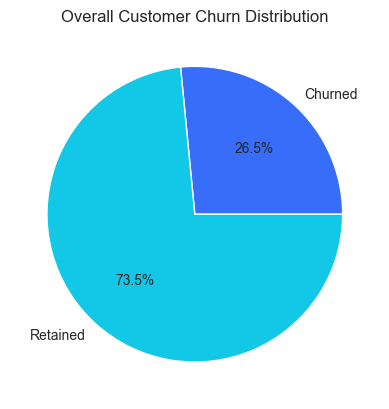

In [20]:
retained= sum(df_clean['Churn Label']=='No')
churned= sum(df_clean['Churn Label']=='Yes')
values= (churned,retained)
labels= ['Churned', 'Retained']
plt.title('Overall Customer Churn Distribution')
plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%'
)
print(f'Churned Customers: {churned} Retained Customers {retained}')
plt.show()

**Interpretation**: This chart highlights the percentage of customers retained and churned. It provides the baseline churn rate for comparison across customer segments with notably higher or lower observed churn rate.

### 4. Customer Characteristics

#### Demographics Analysis
- Gender
- Age Group
- Senior Citizen
- Married
- Dependents
- Under 30
- Satisfaction Score
- Referred a friend

In [21]:
def plot_churn_by_demographic(df, column, ax):
    churn_rate = (
        df.groupby(column)['Churn Label']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .reset_index(name='Churn Rate')
    )

    overall_churn = (df['Churn Label'] == 'Yes').mean() * 100

    bars = ax.bar(
        churn_rate[column],
        churn_rate['Churn Rate']
    )

    ax.axhline(
        y=overall_churn,
        color='red',
        linestyle='--',
        label=f'Overall: {overall_churn:.1f}%'
    )

    ax.set_title(f'Churn Rate by {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Churn Rate (%)')

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f'{bar.get_height():.1f}%',
            ha='center',
            va='bottom'
        )

    ax.legend()

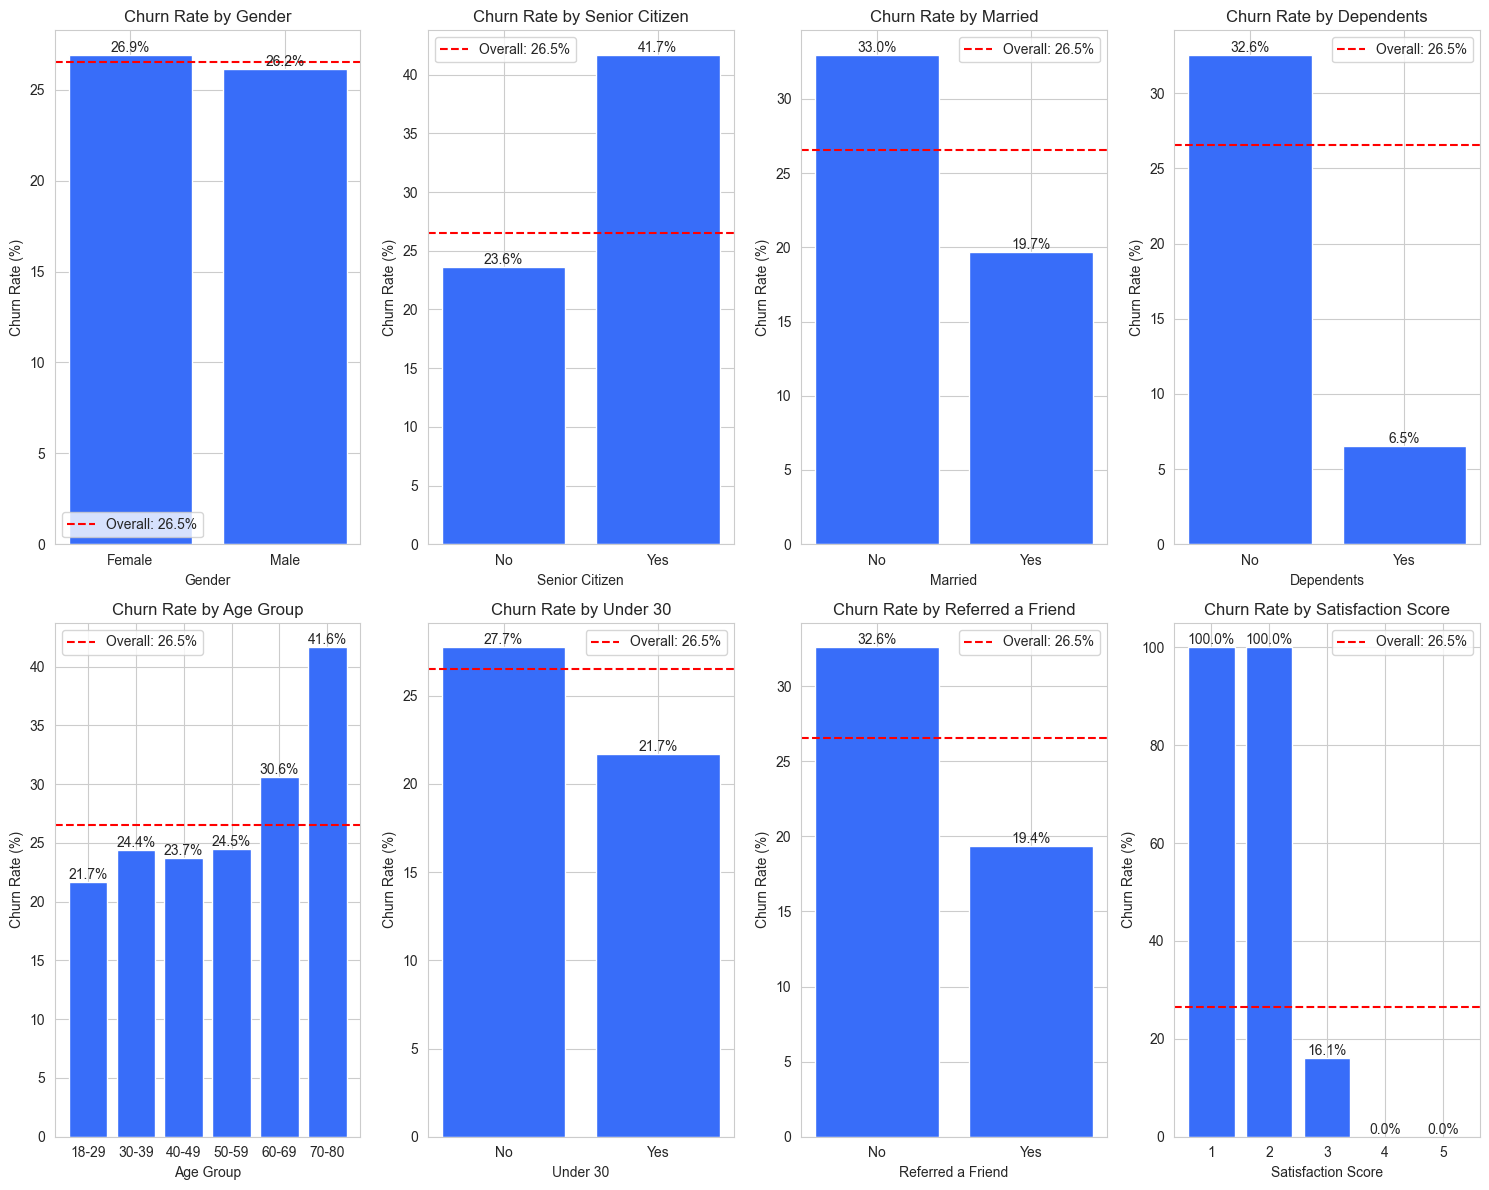

In [22]:
fig, axis = plt.subplots(2,4, figsize=(15,12))
plot_churn_by_demographic(df_clean, 'Gender', axis[0,0])
plot_churn_by_demographic(df_clean, 'Senior Citizen', axis[0,1])
plot_churn_by_demographic(df_clean, 'Married', axis[0,2])
plot_churn_by_demographic(df_clean, 'Dependents', axis[0,3])
plot_churn_by_demographic(df_clean, 'Age Group', axis[1,0])
plot_churn_by_demographic(df_clean, 'Under 30', axis[1,1])
plot_churn_by_demographic(df_clean, 'Referred a Friend', axis[1,2])
plot_churn_by_demographic(df_clean, 'Satisfaction Score', axis[1,3])
plt.tight_layout()

**Insight**: A quick analysis of the categorical variables shows that churn is not evenly distributed across customer categories. Categories
with bars above the overall churn-rate boundary have churn rates higher than the average churn rate across the dataset. These groups may therefore represent customer segments that warrant further investigation.

In [23]:
# Comparing churn rates across contract types for seniors and non-seniors
df_clean.groupby(['Senior Citizen', 'Contract'])['Churn Label'].agg(Customer= 'size', Churn_Rate= lambda x: (x=='Yes').mean() *100) 

Customer  Churn_Rate
Senior Citizen Contract                            
No             Month-to-Month      3068   39.569752
               One Year            1283   10.678098
               Two Year            1550    2.709677
Yes            Month-to-Month       542   81.365314
               One Year             267   10.861423
               Two Year             333    1.801802

In [24]:
# Comparing churn rates across contract types for customers with and without dependents
df_clean.groupby(['Dependents', 'Contract'])['Churn Label'].agg(Customer='size', Churn_Rate= lambda x: (x=='Yes').mean()*100)

Customer  Churn_Rate
Dependents Contract                            
No         Month-to-Month      2999   51.650550
           One Year            1183   14.032122
           Two Year            1234    3.889789
Yes        Month-to-Month       611   17.348609
           One Year             367    0.000000
           Two Year             649    0.000000

In [25]:
df_clean.groupby('Dependents')['Churn Label'].agg(Customer='size', Churn_Rate= lambda x: (x=='Yes').mean()*100)

,Customer,Churn_Rate
Dependents,,
No,5416,32.551699
Yes,1627,6.515058


In [26]:
# Comparing churn rates across tenure groups for customers with and without dependents
df_clean.groupby(['Dependents', 'Tenure Groups'])['Churn Label'].agg(Customer='size', Churn_Rate= lambda x: (x=='Yes').mean()*100)

Customer  Churn_Rate
Dependents Tenure Groups                      
No         1-12 Months        1838   52.339499
           13-24 Months        789   35.361217
           25-36 Months        638   27.115987
           37-48 Months        567   24.514991
           49-60 Months        611   19.148936
           61-72 Months        973    9.558068
Yes        1-12 Months         348   21.551724
           13-24 Months        235    6.382979
           25-36 Months        194    3.608247
           37-48 Months        195    3.076923
           49-60 Months        221    1.357466
           61-72 Months        434    0.000000

In [27]:
# Comparing churn rates across contract types for married and unmarried customers
df_clean.groupby(['Married', 'Contract'])['Churn Label'].agg(Customers='size', Mean= lambda x: (x=='Yes').mean()*100)

Customers       Mean
Married Contract                            
No      Month-to-Month       2343  47.588562
        One Year              677  10.044313
        Two Year              621   2.737520
Yes     Month-to-Month       1267  42.620363
        One Year              873  11.225659
        Two Year             1262   2.456418

In [28]:
# Comparing churn rates across tenure groups for married and unmarried customers 
df_clean.groupby(['Married', 'Tenure Groups'])['Churn Label'].agg(Customers='size', Mean= lambda x: (x=='Yes').mean()*100)

Customers       Mean
Married Tenure Groups                      
No      1-12 Months         1623  48.860136
        13-24 Months         590  29.661017
        25-36 Months         427  21.311475
        37-48 Months         356  20.224719
        49-60 Months         311  14.147910
        61-72 Months         334   7.485030
Yes     1-12 Months          563  43.339254
        13-24 Months         434  27.419355
        25-36 Months         405  21.975309
        37-48 Months         406  17.980296
        49-60 Months         521  14.587332
        61-72 Months        1073   6.337372

In [29]:
df_clean.groupby(['Married'])['Churn Label'].agg(Customers='size', Mean= lambda x: (x=='Yes').mean()*100)

,Customers,Mean
Married,,
No,3641,32.957979
Yes,3402,19.664903


In [30]:
df_clean['Satisfaction Score'].value_counts()

Satisfaction Score
3    2665
4    1789
5    1149
1     922
2     518
Name: count, dtype: int64

#### *Summary Insights*: 
- **Gender:** Gender showed little difference in observed churn in this dataset.
- **Age Group:** Churn generally increased with age. Customers aged 70–80 had a churn rate of 41.6%. Older customers, particularly those in the oldest age group, represent a segment worth examining more closely.                                        
- **Senior Citizen:** Senior citizens had a churn rate of 41.7%, compared with 23.6% for non-senior customers. Senior citizens had substantially higher observed churn, a difference of 18.1 percentage points.                                     
- **Marital Status:** Unmarried customers had a churn rate of 33.0%, compared with 19.6% for married customers. Marital status was associated with churn, although the difference became smaller within tenure groups.                                                   
- **Dependents:** Customers without dependents had a churn rate of 32.6%, compared with 6.5% for customers with dependents. Customers with dependents had considerably lower observed churn. The association also appeared within the tenure groups and contract types.


### 5. Pricing and Customer Value

#### Charges, Revenue & Customer Value
- Monthly Charge
- Total Revenue
- Tenure 
- CLTV


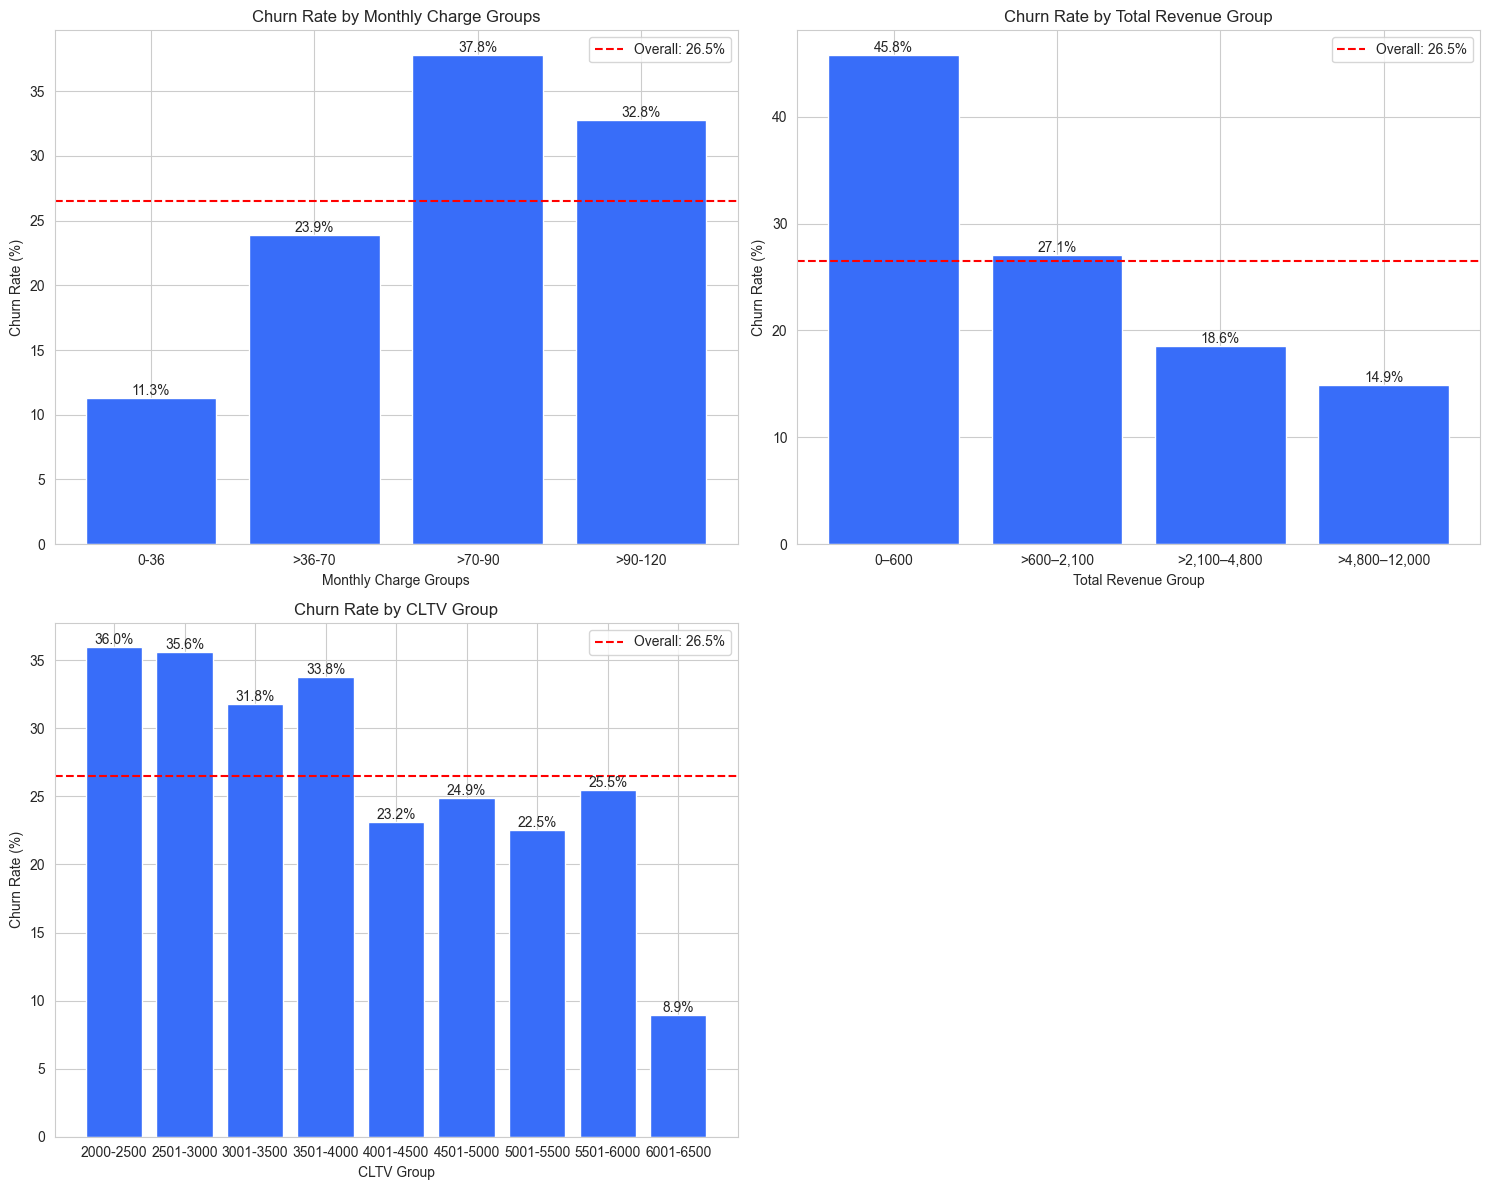

In [31]:
fig, axis = plt.subplots(2,2, figsize=(15,12))
plot_churn_by_demographic(df_clean, 'Monthly Charge Groups', axis[0,0])
plot_churn_by_demographic(df_clean, 'Total Revenue Group', axis[0,1])
plot_churn_by_demographic(df_clean, 'CLTV Group', axis[1,0])
fig.delaxes(axis[1,1])
plt.tight_layout()

#### Tenure Analysis

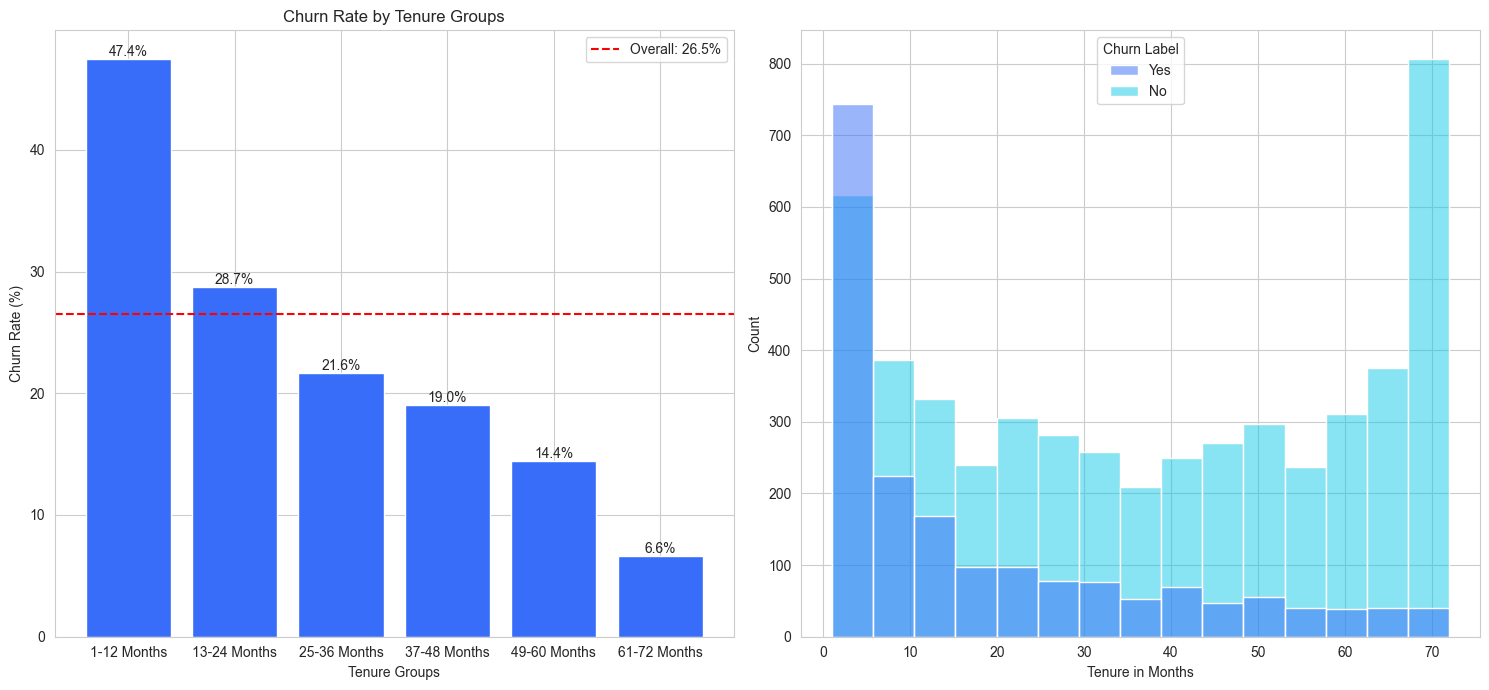

In [32]:
fig, axis= plt.subplots(1,2, figsize=(15,7))
plot_churn_by_demographic(df_clean, 'Tenure Groups', axis[0])
sns.histplot(data=df_clean,x='Tenure in Months', ax=axis[1],hue='Churn Label')
plt.tight_layout()

**Insights:** Churn is markedly higher during the earlier months of the customer relationship, with around **47.4% of customers within the first 12 months churning**, which is **20.9 percentage points above the overall churn rate**. The churn rate then decreases steadily as tenure increases. This indicates a clear association between tenure and churn, although the analysis does not establish that tenure itself causes customers to churn. The pattern may warrant further investigation into factors affecting customers during the early stages of their relationship with the company.


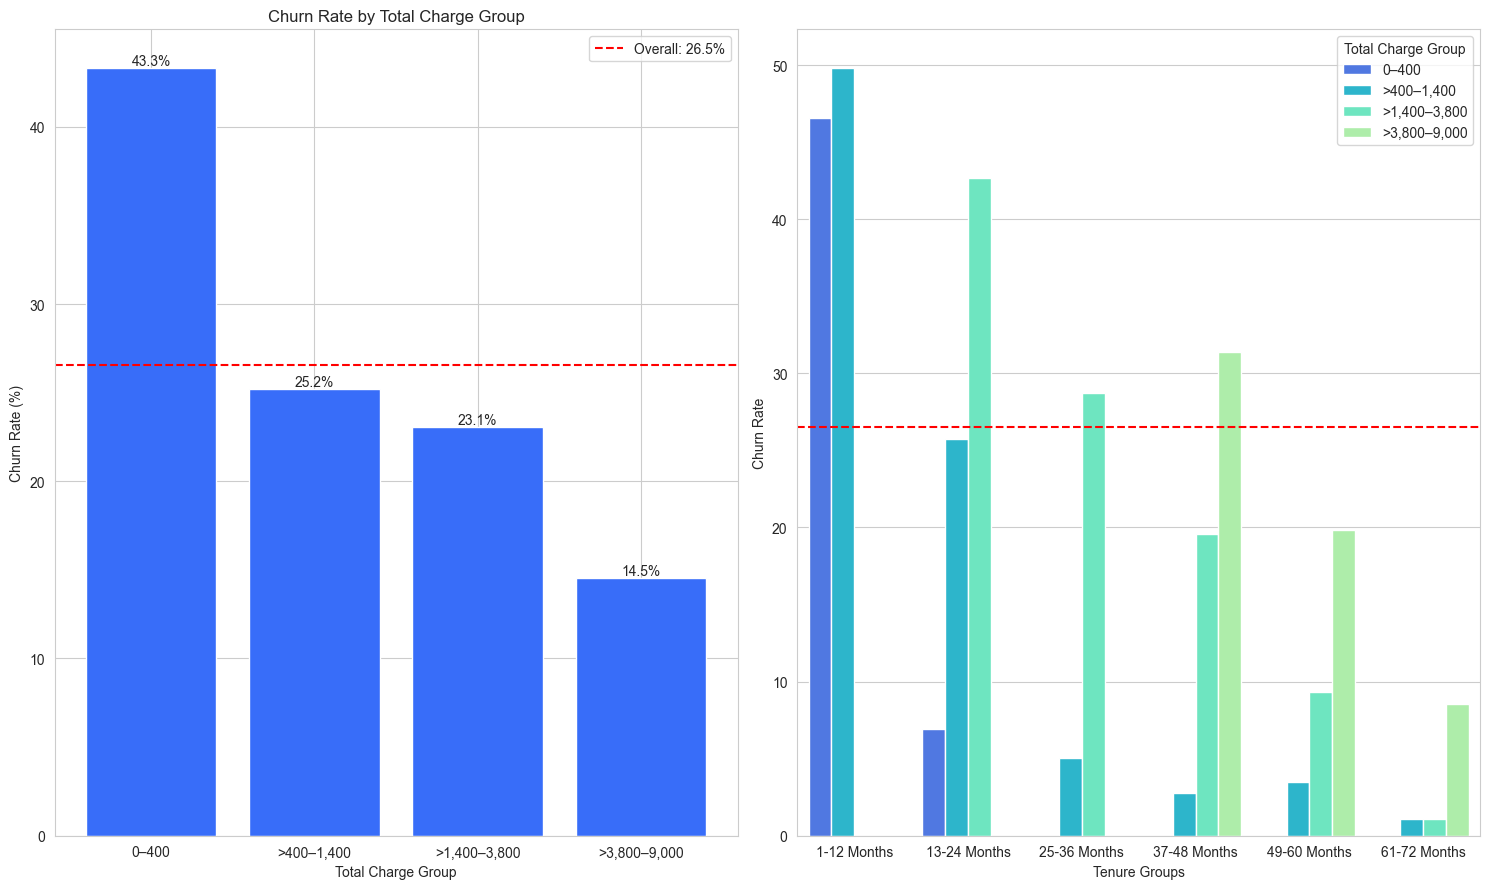

In [33]:
fig, axis = plt.subplots(1,2, figsize=(15,9))
plot_churn_by_demographic(df_clean, 'Total Charge Group',axis[0])
churn_rate = (
    df_clean.groupby(['Tenure Groups', 'Total Charge Group'])['Churn Label']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Churn Rate')
)

overall_churn = (df_clean['Churn Label'] == 'Yes').mean() * 100

ax = sns.barplot(
    data=churn_rate,
    x='Tenure Groups',
    y='Churn Rate',
    hue='Total Charge Group',
    ax=axis[1]
)

ax.axhline(
    y=overall_churn,
    color='red',
    linestyle='--',
    label=f'Overall: {overall_churn:.1f}%'
)
plt.tight_layout()

**Insight:** Tenure and Total Charges are strongly related, as Total Charges accumulate over time. Therefore, I conducted a deeper analysis to determine how churn rates differed between Total Charge groups within each Tenure Group. Generally, higher Total Charge groups show higher churn rates, while churn rates decrease as tenure increases. **This suggests that within each tenure group, customers with higher accumulated charges tend to have higher rates of churn.**


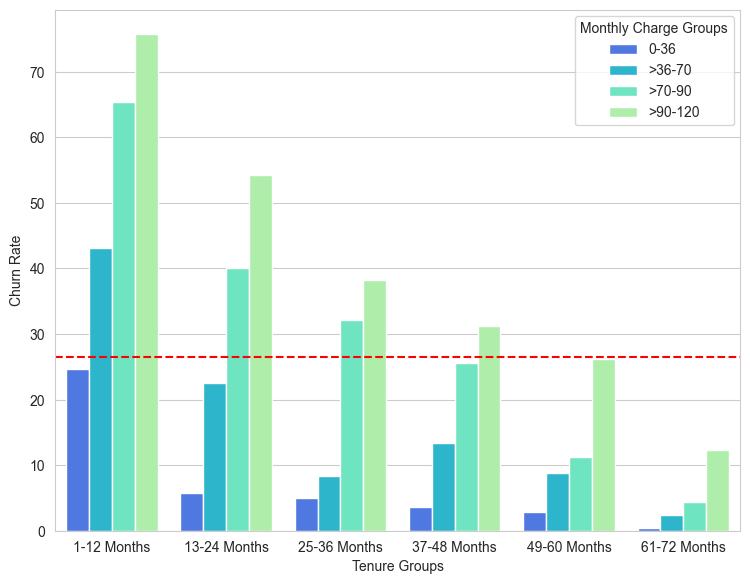

In [34]:
fig, axis = plt.subplots(1,2, figsize=(15,6))
churn_rate = (
    df_clean.groupby(['Tenure Groups', 'Monthly Charge Groups'])['Churn Label']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Churn Rate')
)

overall_churn = (df_clean['Churn Label'] == 'Yes').mean() * 100

ax = sns.barplot(
    data=churn_rate,
    x='Tenure Groups',
    y='Churn Rate',
    hue='Monthly Charge Groups',
    ax=axis[0]
)

ax.axhline(
    y=overall_churn,
    color='red',
    linestyle='--',
    label=f'Overall: {overall_churn:.1f}%'
)
plt.tight_layout()
fig.delaxes(axis[1])

**Insights:** Higher monthly charges are associated with higher observed churn, and this relationship remains visible when comparing customers within similar tenure groups. The strongest churn is concentrated among newer customers with higher monthly charges.

### 6. Contracts and Customer Commitment

#### Contract and Billing
- Contract
- Paperless Billing
- Payment Method
- Offer

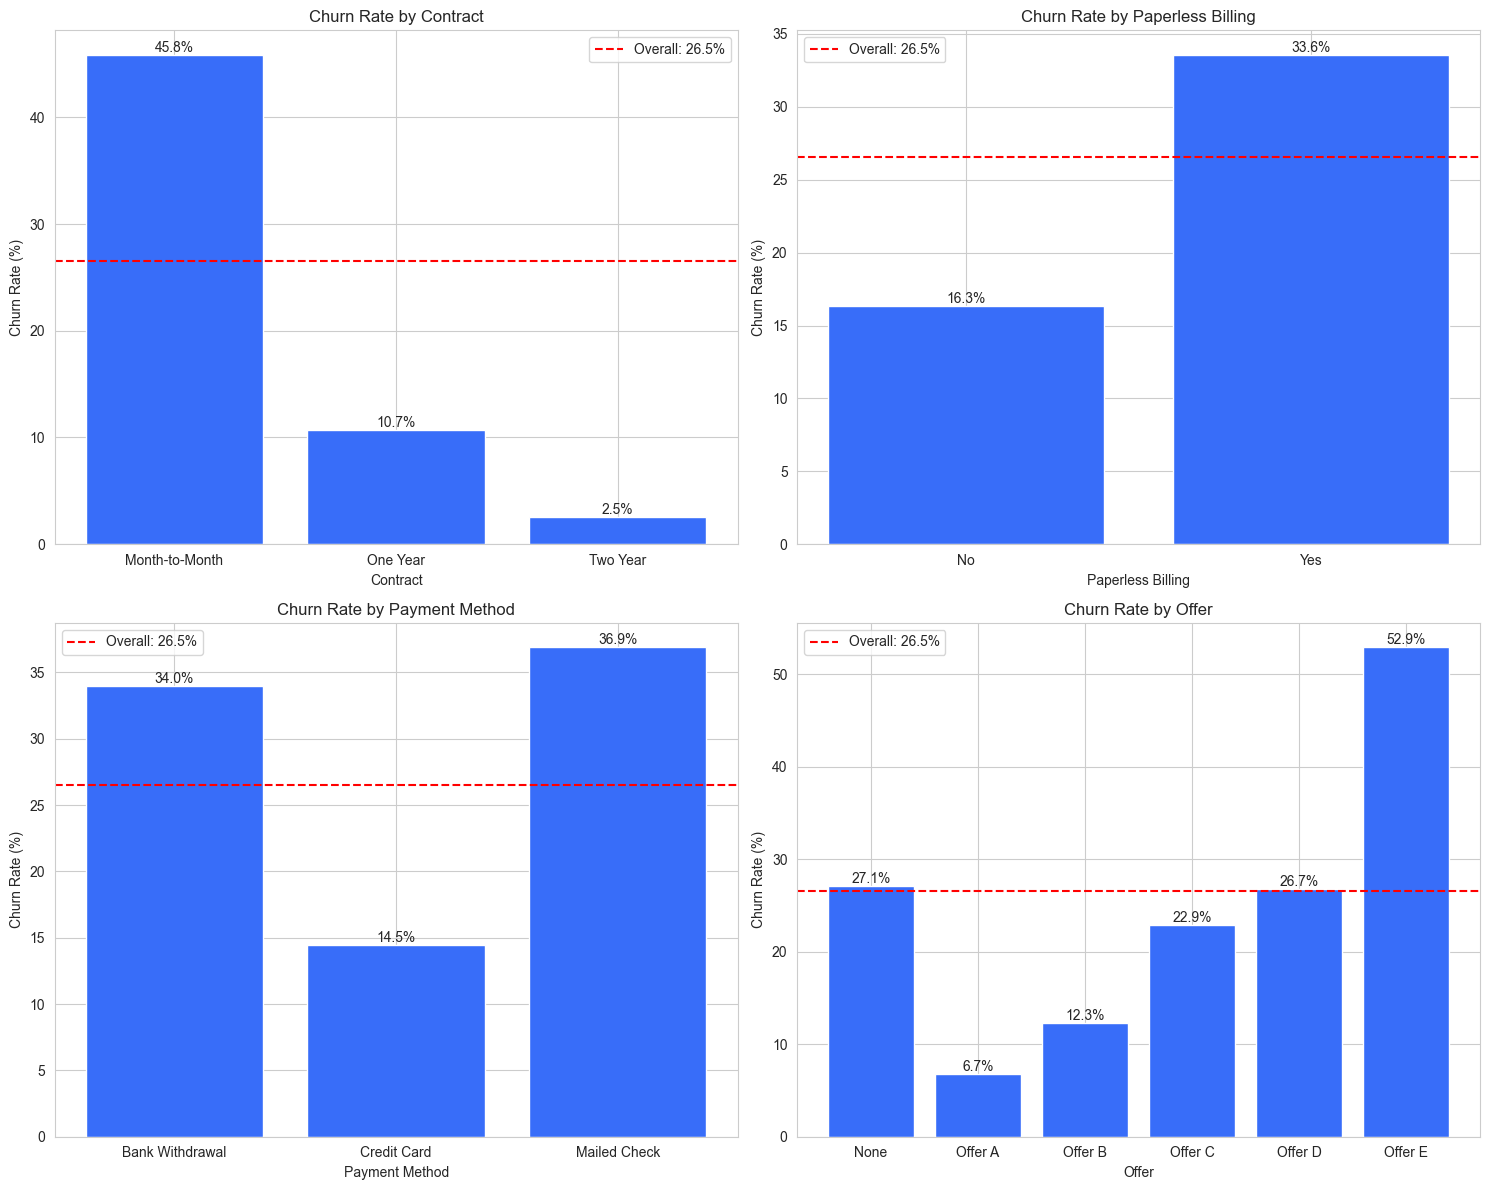

In [35]:
fig, axis = plt.subplots(2,2, figsize=(15,12))
plot_churn_by_demographic(df_clean, 'Contract', axis[0,0])
plot_churn_by_demographic(df_clean, 'Paperless Billing', axis[0,1])
plot_churn_by_demographic(df_clean, 'Payment Method', axis[1,0])
plot_churn_by_demographic(df_clean, 'Offer', axis[1,1])
plt.tight_layout()

#### Contract Anaysis

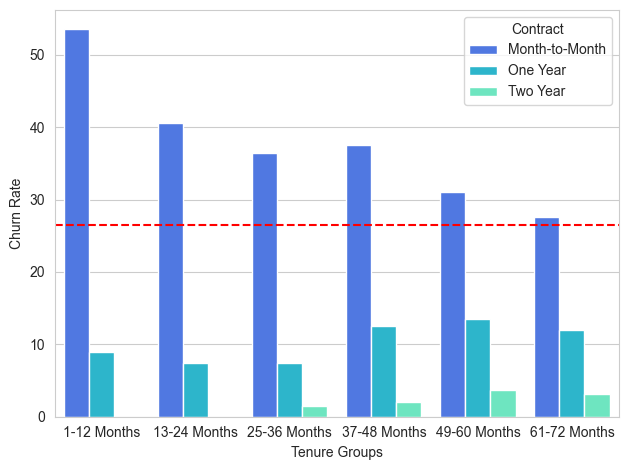

In [36]:
churn_rate = (
    df_clean.groupby(['Tenure Groups', 'Contract'])['Churn Label']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Churn Rate')
)

overall_churn = (df_clean['Churn Label'] == 'Yes').mean() * 100

ax = sns.barplot(
    data=churn_rate,
    x='Tenure Groups',
    y='Churn Rate',
    hue='Contract',
)

ax.axhline(
    y=overall_churn,
    color='red',
    linestyle='--',
    label=f'Overall: {overall_churn:.1f}%'
)
plt.tight_layout()

In [37]:
df_clean.groupby('Contract')['Tenure in Months'].agg(Mean_Tenure= lambda x: x.mean())

,Mean_Tenure
Contract,
Month-to-Month,17.350416
One Year,41.252903
Two Year,53.915560


**Insights:** Month-to-month customers have the highest observed churn rate at 45.8%, with churn generally decreasing as contract length increases. These customers also have shorter average tenure, but the higher churn among month-to-month customers remains when comparing customers within similar tenure groups. **This suggests that the relationship between contract type and churn is not solely explained by tenure**. The higher churn may be associated with characteristics of month-to-month customers, while the lower commitment of this contract type may also make it easier for customers to leave.


#### Payment Method Analysis 

In [38]:
payment_tenure = (
    df_clean
    .groupby(['Payment Method', 'Tenure Groups', 'Contract'])['Churn Label']
    .agg(
        Customers='size',
        Churn_Rate=lambda x: (x == 'Yes').mean() * 100
    )
)

payment_tenure

Customers  Churn_Rate
Payment Method  Tenure Groups Contract                             
Bank Withdrawal 1-12 Months   Month-to-Month       1104   63.677536
                              One Year               53   11.320755
                              Two Year               50    0.000000
                13-24 Months  Month-to-Month        439   48.974943
                              One Year               80   10.000000
                              Two Year               38    0.000000
                25-36 Months  Month-to-Month        282   42.907801
                              One Year              128   10.156250
                              Two Year               56    0.000000
                37-48 Months  Month-to-Month        195   43.589744
                              One Year              152    9.868421
                              Two Year               83    2.409639
                49-60 Months  Month-to-Month        158   34.810127
                              One Year              193   18.134715
                              Two Year              135    6.666667
                61-72 Months  Month-to-Month         62   25.806452
                              One Year              191   13.089005
                              Two Year              510    4.117647
Credit Card     1-12 Months   Month-to-Month        629   32.750397
                              One Year               78    6.410256
                              Two Year               64    0.000000
                13-24 Months  Month-to-Month        213   23.943662
                              One Year              114    5.263158
                              Two Year               78    0.000000
                25-36 Months  Month-to-Month        138   26.086957
                              One Year              122    2.459016
                              Two Year               72    2.777778
                37-48 Months  Month-to-Month         83   22.891566
                              One Year              115   14.782609
                              Two Year              106    1.886792
                49-60 Months  Month-to-Month         50   20.000000
                              One Year              121    6.611570
                              Two Year              152    1.315789
                61-72 Months  Month-to-Month         23   34.782609
                              One Year              121   10.743802
                              Two Year              470    2.127660
Mailed Check    1-12 Months   Month-to-Month        180   63.888889
                              One Year               15   13.333333
                              Two Year               13    0.000000
                13-24 Months  Month-to-Month         34   35.294118
                              One Year               21    9.523810
                              Two Year                7    0.000000
                25-36 Months  Month-to-Month         13    7.692308
                              One Year               18   22.222222
                              Two Year                3    0.000000
                37-48 Months  Month-to-Month          4   50.000000
                              One Year               11   27.272727
                              Two Year               13    0.000000
                49-60 Months  Month-to-Month          1    0.000000
                              One Year               12    8.333333
                              Two Year               10    0.000000
                61-72 Months  Month-to-Month          2    0.000000
                              One Year                5    0.000000
                              Two Year               23    0.000000

**Insight:** Tenure and contract type appear to be strong contrbuting factors associated with churn in the Payement Medthod category, however even within these tenure and contract type groups Credit Card still appears to have lower observed churn rates. This suggests that the difference in churn rates between payment methods is not entirely explained by tenure or contract type, although other customer characteristics may also contribute to the observed differences.

#### Paperless Billing

In [39]:
paper_tenure = (
    df_clean
    .groupby(['Paperless Billing', 'Tenure Groups', 'Contract'])['Churn Label']
    .agg(
        Customers='size',
        Churn_Rate=lambda x: (x == 'Yes').mean() * 100
    )
)

paper_tenure

Customers  Churn_Rate
Paperless Billing Tenure Groups Contract                             
No                1-12 Months   Month-to-Month        733   39.699864
                                One Year               92    7.608696
                                Two Year               75    0.000000
                  13-24 Months  Month-to-Month        210   24.761905
                                One Year              129    3.875969
                                Two Year               74    0.000000
                  25-36 Months  Month-to-Month        141   20.567376
                                One Year              131    3.816794
                                Two Year               73    1.369863
                  37-48 Months  Month-to-Month         74   27.027027
                                One Year              120    6.666667
                                Two Year              118    0.847458
                  49-60 Months  Month-to-Month         47   25.531915
                                One Year              116   11.206897
                                Two Year              164    2.439024
                  61-72 Months  Month-to-Month         17   11.764706
                                One Year              105    9.523810
                                Two Year              453    1.986755
Yes               1-12 Months   Month-to-Month       1180   62.118644
                                One Year               54   11.111111
                                Two Year               52    0.000000
                  13-24 Months  Month-to-Month        476   47.478992
                                One Year               86   12.790698
                                Two Year               49    0.000000
                  25-36 Months  Month-to-Month        292   44.178082
                                One Year              137   10.948905
                                Two Year               58    1.724138
                  37-48 Months  Month-to-Month        208   41.346154
                                One Year              158   17.088608
                                Two Year               84    3.571429
                  49-60 Months  Month-to-Month        162   32.716049
                                One Year              210   14.761905
                                Two Year              133    5.263158
                  61-72 Months  Month-to-Month         70   31.428571
                                One Year              212   13.207547
                                Two Year              550    4.000000

In [40]:
df_clean['Paperless Billing'].value_counts()

Paperless Billing
Yes    4171
No     2872
Name: count, dtype: int64

**Insight:** Customers using paperless billing have a higher observed churn rate than those who do not. This difference remains when comparing customers within similar tenure and contract groups, suggesting that the association is not solely explained by these factors. However, paperless billing is primarily a billing preference rather than a customer behavior the business would necessarily want to change, so it is noted as an associated characteristic but does not warrant further investigation.


### 7. Services and Customer Engagement

#### Internet and Data Usage 
- Internet Service
- Internet Type
- Avg Monthly GB Download
- Unlimited Data

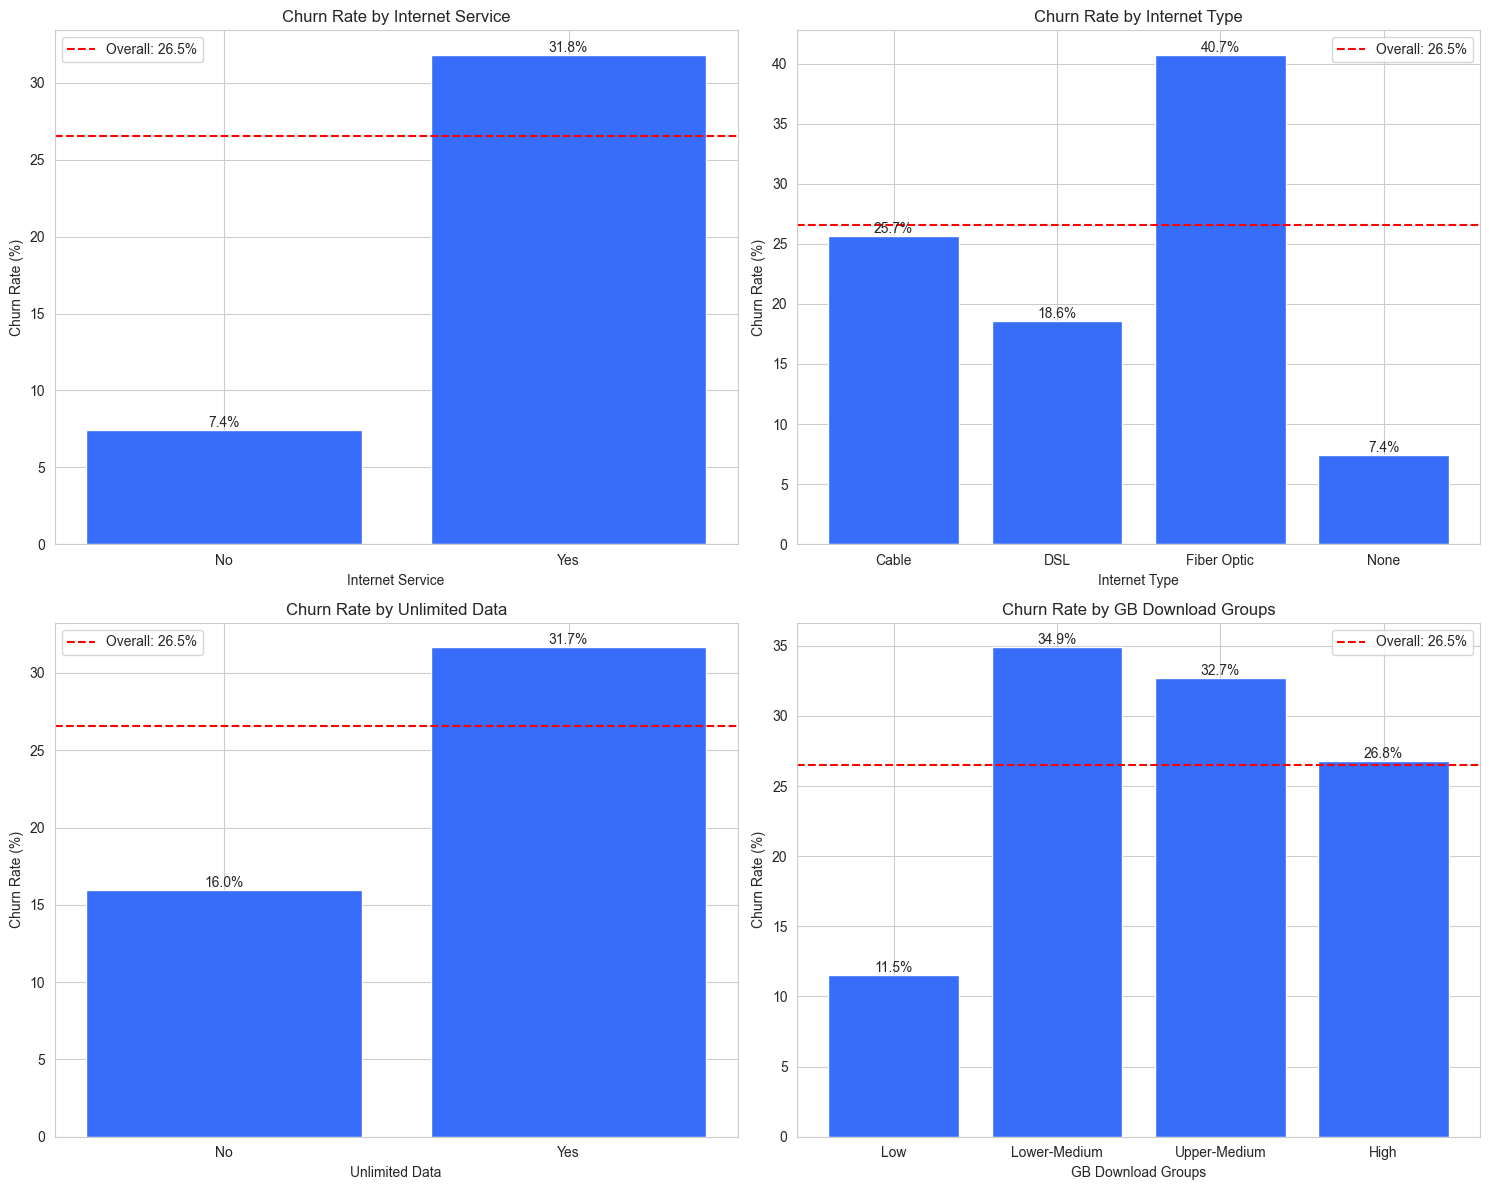

In [41]:
fig, axis = plt.subplots(2,2, figsize=(15,12))
plot_churn_by_demographic(df_clean, 'Internet Service', axis[0,0])
plot_churn_by_demographic(df_clean, 'Internet Type', axis[0,1])
plot_churn_by_demographic(df_clean, 'Unlimited Data', axis[1,0])
plot_churn_by_demographic(df_clean, 'GB Download Groups', axis[1,1])
plt.tight_layout()

#### Internet Service & Unlimited Data

In [42]:
df_clean[df_clean['Internet Service'] == 'Yes'].groupby('Unlimited Data')['Churn Label'].agg(
    Customers='size',
    Churn_Rate=lambda x: (x == 'Yes').mean() * 100
)

,Customers,Churn_Rate
Unlimited Data,,
No,772,32.901554
Yes,4745,31.654373


**Insight:** Further analysis of Unlimited Data reveals that churn rates are similar among customers who have Internet Service, regardless of whether they have Unlimited Data. Therefore, it may be worth focusing more closely on Internet Service.


In [43]:
df_clean.groupby(['Internet Service', 'Tenure Groups'])['Churn Label'].agg(Customers='size', Churn_Rate= lambda x: (x=='Yes').mean()*100)

Customers  Churn_Rate
Internet Service Tenure Groups                       
No               1-12 Months          513   17.933723
                 13-24 Months         239    3.765690
                 25-36 Months         170    2.941176
                 37-48 Months         167    0.598802
                 49-60 Months         161    3.105590
                 61-72 Months         276    0.362319
Yes              1-12 Months         1673   56.485356
                 13-24 Months         785   36.305732
                 25-36 Months         662   26.435045
                 37-48 Months         595   24.201681
                 49-60 Months         671   17.138599
                 61-72 Months        1131    8.134394

In [44]:
df_clean.groupby(['Internet Service', 'Monthly Charge Groups'])['Churn Label'].agg(Customers='size', Churn_Rate= lambda x: (x=='Yes').mean()*100)

Customers  Churn_Rate
Internet Service Monthly Charge Groups                       
No               0-36                        1526    7.404980
Yes              0-36                         257   34.241245
                 >36-70                      1677   23.911747
                 >70-90                      1844   37.798265
                 >90-120                     1739   32.777458

In [45]:
df_clean.groupby(['Internet Service'])['Churn Label'].agg(Customers='size', Churn_Rate= lambda x: (x=='Yes').mean()*100)

,Customers,Churn_Rate
Internet Service,,
No,1526,7.404980
Yes,5517,31.828893


In [46]:
df_clean.groupby(['Internet Service', 'Contract'])['Churn Label'].agg(Customers='size', Churn_Rate= lambda x: (x=='Yes').mean()*100)

Customers  Churn_Rate
Internet Service Contract                             
No               Month-to-Month        518   19.111969
                 One Year              366    2.459016
                 Two Year              642    0.778816
Yes              Month-to-Month       3092   50.323415
                 One Year             1184   13.260135
                 Two Year             1241    3.464948

**Insight:** Customers with Internet Service have higher observed churn rates than those without it across all tenure groups. Although churn generally decreases as tenure increases for both groups, the difference in churn rates persists throughout and also within contract groups. The smaller customer counts among those without Internet Service mean that some of their churn-rate estimates may be less stable.


In [47]:
df_clean.groupby('Internet Type')['Monthly Charge'].agg(Customers='size', Mean= lambda x: x.mean())

,Customers,Mean
Internet Type,,
Cable,830,60.277530
DSL,1652,58.183172
Fiber Optic,3035,91.532389
None,1526,21.079194


**Insight:** Fiber Optic internet type shows a significantly higher churn rate, this could be due to having higher customer counts therefore higher variation in customer behaviours. It is also important to not that the mean Monthly Charge for Fiber Optic customers is markedly higher than other internet type. Considering Fiber Optic internet is more expensive, this could be due to price.

#### Additional Services
- Online Security
- Online Backup
- Device Protection Plan
- Premium Tech Support
- Streaming TV
- Streaming Movies
- Streaming Music

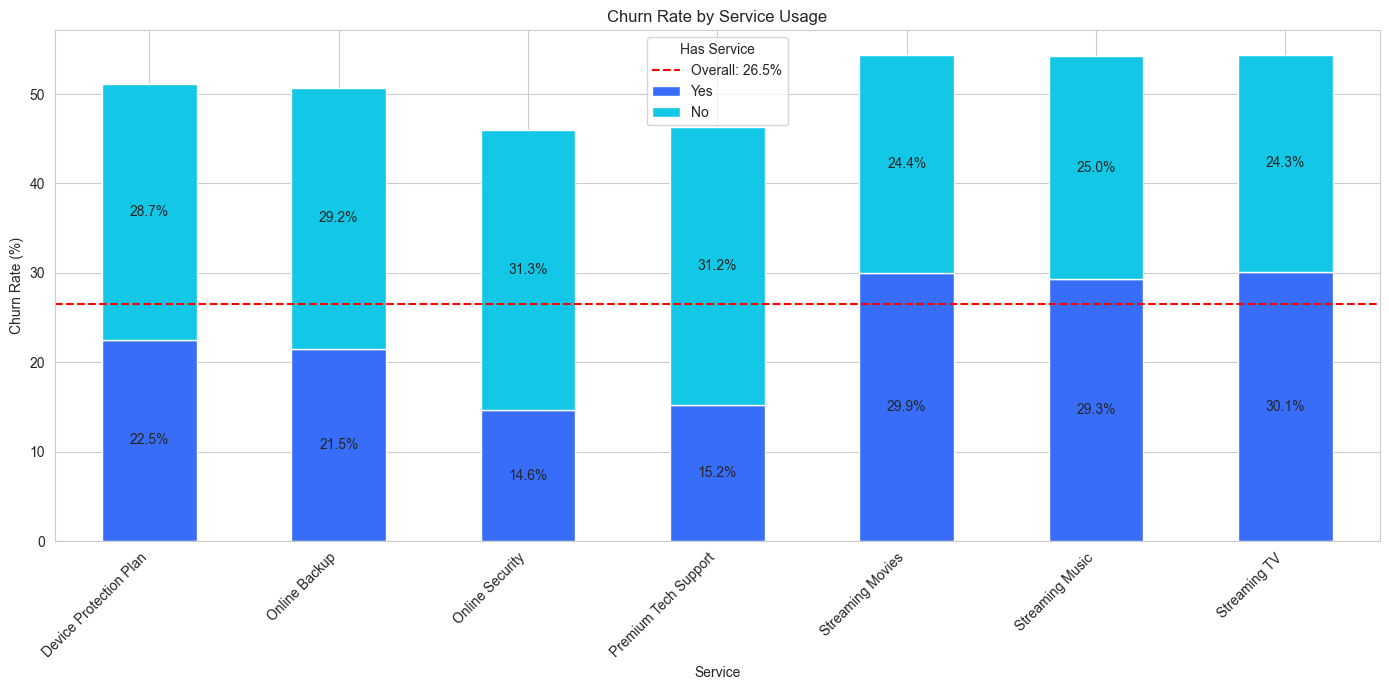

In [48]:
service_cols = [
    'Online Security',
    'Online Backup',
    'Device Protection Plan',
    'Premium Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Streaming Music',
]
service_long = df_clean.melt(
    id_vars='Churn Label',
    value_vars=service_cols,
    var_name='Service',
    value_name='Has Service'
)
overall_churn = (df_clean['Churn Label'] == 'Yes').mean() * 100

churn_rates = (
    service_long
    .groupby(['Service', 'Has Service'])['Churn Label']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .unstack()
)

churn_rates = churn_rates[['Yes', 'No']]
ax = churn_rates.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7)
)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        label_type='center'
    )
ax.axhline(
    y=overall_churn,
    color='red',
    linestyle='--',
    label=f'Overall: {overall_churn:.1f}%'
)
ax.set_xlabel('Service')
ax.set_ylabel('Churn Rate (%)')
ax.set_title('Churn Rate by Service Usage')
ax.legend(title='Has Service')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Insights:** Generally, higher churn rates are more prevalent among customers without add-on services. Online Security and Premium Tech Support, in particular, have the lowest churn rates among customers who use these services. However, streaming services show the opposite pattern, with slightly higher churn rates among customers who use them. This relationship could be associated with a range of customer characteristics and requires further investigation.


### 8. Offers and Retention Opportunities

In [49]:
offer = (
    df_clean
    .groupby(['Offer'])['Churn Label']
    .agg(
        Customers='size',
        Churn_Rate=lambda x: (x == 'Yes').mean() * 100
    )
)

offer

,Customers,Churn_Rate
Offer,,
None,3877,27.108589
Offer A,520,6.730769
Offer B,824,12.257282
Offer C,415,22.891566
Offer D,602,26.744186
Offer E,805,52.919255


In [50]:
offer_summary = (
    df_clean
    .groupby('Offer')
    .agg(
        Customers=('Customer ID', 'size'),
        Avg_Tenure=('Tenure in Months', 'mean'),
        Month_to_Month=('Contract', lambda x: (x == 'Month-to-Month').mean() * 100),
        First_Year=('Tenure in Months', lambda x: (x <= 12).mean() * 100),
        Churn_Rate=('Churn Label', lambda x: (x == 'Yes').mean() * 100)
    )
)

offer_summary

,Customers,Avg_Tenure,Month_to_Month,First_Year,Churn_Rate
Offer,,,,,
None,3877,31.566159,52.102141,31.467630,27.108589
Offer A,520,70.000000,2.884615,0.000000,6.730769
Offer B,824,53.358010,26.213592,0.000000,12.257282
Offer C,415,30.761446,48.915663,0.000000,22.891566
Offer D,602,15.951827,72.093023,26.744186,26.744186
Offer E,805,3.704348,89.689441,100.000000,52.919255


**Insight:** Offer E has the highest observed churn rate among all offers (52.92%). While this could be associated with several factors, it is important to note that 100% of Offer E customers are in their first year, 89.7% use a Month-to-Month contract, and their average tenure is only 3.7 months. Given that shorter tenure and Month-to-Month contracts are both associated with higher churn in the dataset, the high churn rate observed for Offer E may partly reflect its customer composition rather than the offer itself.

### 9. Geographic Analysis

#### City Analysis

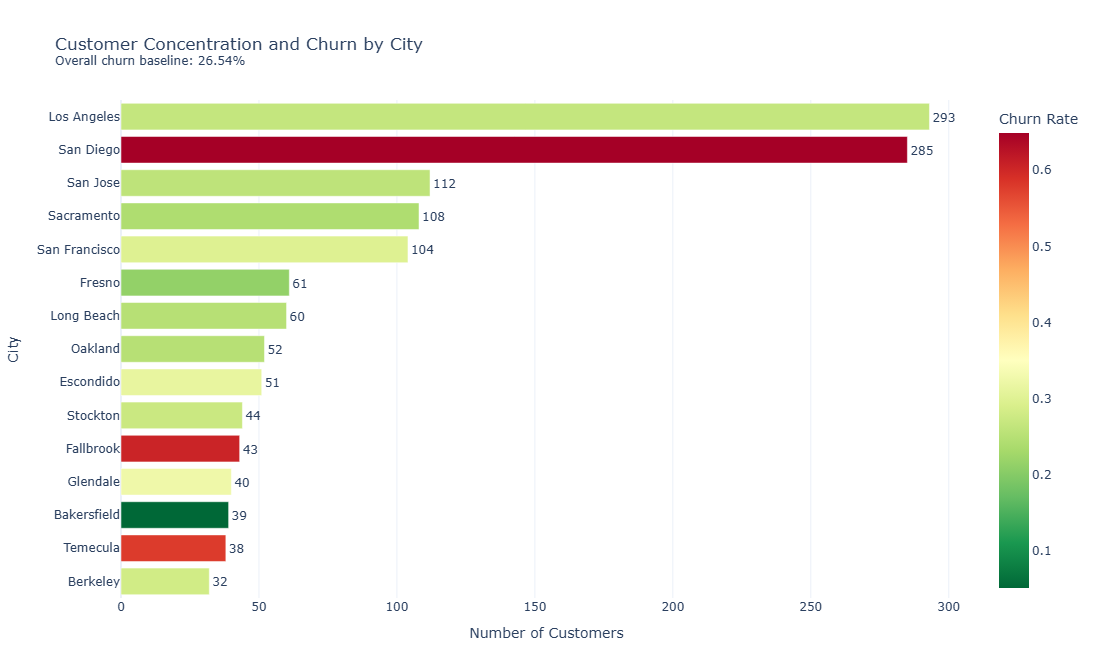

In [51]:
df_clean['Churn Indicator'] = df_clean['Churn Label'].map({'Yes': 1, 'No': 0})
baseline_churn = df_clean['Churn Indicator'].mean()


city_summary = (
    df_clean.groupby('City')
    .agg(
        customer_count=('Customer ID', 'count'),
        churned_customers=('Churn Indicator', 'sum'),
        churn_rate=('Churn Indicator', 'mean')
    )
    .reset_index()
)


total_customers = city_summary['customer_count'].sum()
total_churned = city_summary['churned_customers'].sum()

city_summary['customer_share'] = (
    city_summary['customer_count'] / total_customers * 100
)

city_summary['churn_contribution'] = (
    city_summary['churned_customers'] / total_churned * 100
)


city_summary['above_baseline'] = (
    city_summary['churn_rate'] > baseline_churn
)


top_cities = (
    city_summary
    .nlargest(15, 'customer_count')
    .sort_values('customer_count', ascending=True)
)


fig = px.bar(
    top_cities,
    x='customer_count',
    y='City',
    orientation='h',
    color='churn_rate',
    color_continuous_scale='RdYlGn_r',
    text='customer_count',
    hover_name='City',
    hover_data={
        'customer_count': ':,',
        'customer_share': ':.2f',
        'churned_customers': ':,',
        'churn_rate': ':.2%',
        'churn_contribution': ':.2f',
        'above_baseline': True,
        'City': False
    },
    labels={
        'customer_count': 'Number of Customers',
        'City': 'City',
        'churn_rate': 'Churn Rate',
        'customer_share': 'Customer Base Share (%)',
        'churned_customers': 'Churned Customers',
        'churn_contribution': 'Total Churn Contribution (%)',
        'above_baseline': 'Above Churn Baseline'
    },
    title=(
        f'Customer Concentration and Churn by City'
        f'<br><sup>Overall churn baseline: {baseline_churn:.2%}</sup>'
    )
)

fig.update_traces(
    textposition='outside',
    cliponaxis=False
)

fig.update_layout(
    template='plotly_white',
    height=650,
    xaxis_title='Number of Customers',
    yaxis_title='City',
    coloraxis_colorbar_title='Churn Rate',
    margin=dict(l=20, r=80, t=100, b=40)
)

fig.show()



In [52]:
san=df_clean[df_clean['City']== 'San Diego']

In [53]:
san['Contract'].value_counts()

Contract
Month-to-Month    200
One Year           54
Two Year           31
Name: count, dtype: int64

In [54]:
san['Tenure Groups'].value_counts()

Tenure Groups
1-12 Months     119
13-24 Months     45
25-36 Months     33
37-48 Months     30
61-72 Months     30
49-60 Months     28
Name: count, dtype: int64

In [55]:
san['Monthly Charge Groups'].value_counts()

Monthly Charge Groups
>70-90     105
>90-120     78
>36-70      62
0-36        40
Name: count, dtype: int64

In [56]:
san['Monthly Charge'].mean()

np.float64(72.0219298245614)

In [57]:
san.groupby(['Contract', 'Tenure Groups'])['Churn Label'].agg(Customer= 'size', Churn_Rate= lambda x: (x=='Yes').mean() *100) 

Customer  Churn_Rate
Contract       Tenure Groups                      
Month-to-Month 1-12 Months         114   87.719298
               13-24 Months         34   73.529412
               25-36 Months         27   81.481481
               37-48 Months         15   66.666667
               49-60 Months          6   66.666667
               61-72 Months          4   75.000000
One Year       1-12 Months           5   20.000000
               13-24 Months          8   12.500000
               25-36 Months          4    0.000000
               37-48 Months          8   25.000000
               49-60 Months         18   38.888889
               61-72 Months         11   54.545455
Two Year       13-24 Months          3    0.000000
               25-36 Months          2    0.000000
               37-48 Months          7   14.285714
               49-60 Months          4   75.000000
               61-72 Months         15    0.000000

In [58]:
la=df_clean[df_clean['City']== 'Los Angeles']

In [59]:
la.groupby(['Contract', 'Tenure Groups'])['Churn Label'].agg(Customer= 'size', Churn_Rate= lambda x: (x=='Yes').mean() *100) 

Customer  Churn_Rate
Contract       Tenure Groups                      
Month-to-Month 1-12 Months          77   57.142857
               13-24 Months         27   44.444444
               25-36 Months         21   33.333333
               37-48 Months         14   35.714286
               49-60 Months         12   41.666667
               61-72 Months          3    0.000000
One Year       1-12 Months           9    0.000000
               13-24 Months          6    0.000000
               25-36 Months         10    0.000000
               37-48 Months         11   18.181818
               49-60 Months         11    9.090909
               61-72 Months         16   12.500000
Two Year       1-12 Months           8    0.000000
               13-24 Months          9    0.000000
               25-36 Months          4    0.000000
               37-48 Months          8    0.000000
               49-60 Months          9    0.000000
               61-72 Months         38    0.000000

**Summary Insight:** Churn rates varied considerably across the 15 most frequent cities. Los Angeles had the largest customer base, with a churn rate close to the overall dataset average, while San Diego showed a substantially higher churn rate. Further analysis revealed that San Diego had high churn rates among month-to-month customers across tenure groups, whereas Los Angeles generally showed lower churn rates within comparable contract and tenure groups. These findings suggest that the geographic differences observed are not explained by customer counts alone, although smaller group sizes in some comparisons may make individual churn-rate estimates less stable.


### 10. Churn Reason Analysis 

In [60]:
df_clean['Churn Category'].value_counts()

Churn Category
Competitor         841
Attitude           314
Dissatisfaction    303
Price              211
Other              200
Name: count, dtype: int64

In [61]:
df_clean[df_clean['Churn Category']=='Competitor']['Churn Reason'].value_counts()

Churn Reason
Competitor had better devices                313
Competitor made better offer                 311
Competitor offered more data                 117
Competitor offered higher download speeds    100
Name: count, dtype: int64

In [62]:
df_clean[(df_clean['Churn Category']=='Competitor') & (df_clean['Churn Reason']=='Competitor made better offer')]['Offer'].value_counts()

Offer
None       174
Offer E     78
Offer C     21
Offer D     19
Offer B     13
Offer A      6
Name: count, dtype: int64

In [63]:
df_clean[df_clean['Churn Category']=='Attitude']['Churn Reason'].value_counts()

Churn Reason
Attitude of support person      220
Attitude of service provider     94
Name: count, dtype: int64

In [64]:
df_clean[df_clean['Churn Category']=='Dissatisfaction']['Churn Reason'].value_counts()

Churn Reason
Product dissatisfaction             77
Network reliability                 72
Service dissatisfaction             63
Limited range of services           37
Lack of self-service on Website     29
Poor expertise of online support    13
Poor expertise of phone support     12
Name: count, dtype: int64

In [65]:
df_clean[df_clean['Churn Category']=='Price']['Churn Reason'].value_counts()

Churn Reason
Price too high                              78
Long distance charges                       64
Extra data charges                          39
Lack of affordable download/upload speed    30
Name: count, dtype: int64

In [66]:
df_clean[df_clean['Churn Category']=='Other']['Churn Reason'].value_counts()

Churn Reason
Don't know                          130
Moved                                46
Poor expertise of online support     18
Deceased                              6
Name: count, dtype: int64

In [67]:
df_clean[(df_clean['Churn Category']=='Other') & (df_clean['Churn Reason']=='Moved')]['City'].value_counts()

City
San Jose            3
Long Beach          3
Los Angeles         3
Camarillo           2
Oakland             2
San Francisco       2
Squaw Valley        1
Nipomo              1
North Hollywood     1
Lucerne             1
South Dos Palos     1
Tollhouse           1
Long Barn           1
Mariposa            1
Mi Wuk Village      1
Igo                 1
Lakehead            1
Buellton            1
Morro Bay           1
Downieville         1
Dunnigan            1
El Monte            1
Glendora            1
Carpinteria         1
Berkeley            1
Wheatland           1
Emigrant Gap        1
Meadow Vista        1
Capistrano Beach    1
Corona Del Mar      1
Costa Mesa          1
Sunnyvale           1
Mendocino           1
Navarro             1
Beaumont            1
Cabazon             1
Calipatria          1
Name: count, dtype: int64

#### *Summary Insights*

* **Competitor-related reasons** accounted for the largest share of recorded churn reasons, at 44.9%. These included customers reporting better offers, devices, and larger data allowances from competitors.
* **Customer support and service experience** were also prominent, with the attitude of support personnel and dissatisfaction with the service among the frequently reported reasons for churn.
* **Price and other factors** accounted for additional departures, suggesting that customers reported a range of reasons for leaving.

**Business Implication:** The findings suggest that the company could investigate its competitive position, customer-support experience, and service quality to identify potential retention opportunities. However, these are customer-reported reasons among those who churned and do not establish that any single factor independently caused churn.


### 11. Key Findings and Business Implications

The analysis revealed several patterns associated with customer churn, highlighting areas where the company could investigate potential retention opportunities.

### 11.1 Key Findings

**1. Overall Customer Churn**

The overall churn rate was approximately 26.54%, meaning that more than one in four customers in the dataset had churned during the observed period(Q3). This provides a baseline for comparing churn rates across customer characteristics, contracts, services, and locations.

**2. Customer Tenure**

Customers in their first 12 months had an observed churn rate of approximately 47.4%, with churn generally decreasing as tenure increased. This highlights the early customer relationship as an important area for further investigation.

**3. Contract Type**

Customers on month-to-month contracts had an observed churn rate of approximately 45.8%, considerably higher than customers on longer-term contracts. This pattern suggests that contract type is an important characteristic to consider when examining customer retention.

**4. Customer Age**

Older customers consistently showed higher observed churn across several age-related comparisons. Customers aged 70–80 recorded a churn rate of 41.6%. This pattern highlights the importance of understanding how customer experiences and needs may differ across age groups.

**5. Geographic Variation**

Churn varied considerably across cities. San Diego had an observed churn rate of approximately 64.9%, compared with approximately 26.6% in Los Angeles and an overall dataset churn rate of 26.54%. Further analysis showed differences in churn across contract types and tenure groups within these cities, although some subgroup estimates were based on small customer counts.

**6. Customer Satisfaction**

All customers who gave satisfaction scores of 1 or 2 churned. Together, these customers accounted for approximately 77% of all churned customers (1,440 of 1,869). No churn was observed among customers who gave satisfaction scores of 4 or 5. These patterns highlight a strong association between recorded satisfaction scores and churn status in this dataset.

**7. Reported Reasons for Churn**

Competitor-related reasons accounted for 44.9% of recorded churn reasons, making this the most frequently reported category. Customers also frequently cited the attitude of support personnel and dissatisfaction with the service. Price and other factors accounted for additional departures.

**8. Internet Type**

Customers with Fiber Optic internet service had a higher observed churn rate than customers using other internet types. Fiber Optic customers also had a higher average monthly charge. These findings highlight a potential area for further investigation into whether differences in pricing, customer experience, or other customer characteristics are associated with the observed churn pattern.

### 11.2 Business Implications

The findings identify several areas for further investigation:

* **Early retention:** Investigate the experiences of new customers, particularly during their first 12 months, to understand the high observed churn rate during this period.
* **Contract type:** Examine why month-to-month customers leave more frequently and whether their concerns differ from those of customers on longer-term contracts.
* **Customer experience:** Investigate low satisfaction scores, support experiences, and service dissatisfaction to identify potential opportunities to improve retention.
* **Geographic differences:** Examine the unusually high churn observed in San Diego to determine whether local customer characteristics or experiences help explain the difference.
* **Competitive positioning:** Review the offers, devices, and data allowances customers report receiving from competitors to identify areas where the company's offering could be examined further.
* **Customer needs:** Investigate whether service expectations or support requirements differ across age groups, without assuming that age itself explains churn.

These findings describe observed patterns and customer-reported reasons rather than establishing causation. Further investigation would be required to determine the underlying explanations for these patterns and whether particular retention interventions would be effective.



### 12. Conclusion and Limitations

### 12.1 Conclusion

This project analysed customer churn in a telecommunications dataset containing 7,043 customer records to identify patterns associated with customer retention and highlight potential areas for further business investigation.

The analysis found an overall churn rate of approximately 26.54%, with substantial differences across customer groups. Churn was particularly high among customers in their first year and those on month-to-month contracts. Older customers also consistently showed higher observed churn across several comparisons, while San Diego stood out as a city with an unusually high churn rate.

Customer satisfaction and reported reasons for leaving provided additional insight into the churn patterns. All customers who gave satisfaction scores of 1 or 2 had churned, while competitor-related reasons accounted for 44.9% of recorded churn reasons. Support-personnel attitude and service dissatisfaction were also frequently reported.

Overall, the findings identify several areas the business could investigate further, including early customer retention, customer support, competitive positioning, and geographic differences in churn. However, these findings describe observed patterns rather than establishing why customers leave. Further investigation would be necessary to understand the underlying explanations and evaluate potential retention strategies.

### 12.2 Limitations

Several limitations should be considered when interpreting the findings:

* **Observational analysis:** The project examined patterns and associations in the available data. It did not establish causal relationships between customer characteristics and churn.
* **Customer-reported churn reasons:** Recorded reasons reflect the explanations provided by customers who churned. They may not capture every contributing factor and cannot establish how frequently a particular issue occurs among customers who remain.
* **Satisfaction and churn:** The strong relationship observed between satisfaction scores and churn does not establish whether dissatisfaction preceded churn or caused customers to leave.
* **Small subgroup sizes:** Some comparisons, particularly those involving individual cities and combinations of contract type and tenure, contained relatively few customers. Churn rates in these groups may therefore be less stable.
* **Potentially overlapping characteristics:** Customer characteristics such as age, tenure, contract type, and monthly charges may be related. The descriptive comparisons do not isolate the independent contribution of each characteristic.
* **Dataset scope:** The analysis used the available dataset and its recorded customer information. The findings may not generalise to other telecommunications providers, customer populations, or periods.
* **Unclear variable definitions:** Some financial variables, particularly Customer Lifetime Value (CLTV) and Total Revenue, were not fully explained by the available documentation. Their results were therefore interpreted cautiously and were not treated as definitive measures of actual revenue or future customer value.

Despite these limitations, the project provides a structured overview of customer churn patterns and identifies areas for further investigation. The findings can serve as a starting point for more targeted analysis and future evaluation of customer-retention initiatives.
